# P1 — qualidade da base

Auditoria agregada da base v7. Nenhuma linha individual é exibida ou removida. Grupos com 1 a 9 alunos são suprimidos, inclusive percentuais que permitiriam recuperá-los. Zero é exibido. A aprovação das decisões pela Karolina permanece para a revisão do PR.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

raiz = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(raiz))
from src.dados import carregar_base
from src.config import caminho_base

base = carregar_base()
original = pd.read_csv(caminho_base(), sep=';', encoding='utf-8', dtype='string', keep_default_na=True)
figuras = raiz / 'reports' / 'figures'
figuras.mkdir(parents=True, exist_ok=True)

def alunos(mask):
    return base.loc[mask.fillna(False), 'HANDLEALUNO'].nunique()

def seguro(n, pessoas):
    return int(n) if n == 0 or pessoas >= 10 else '<10 alunos'

def resumo(mascaras):
    return pd.DataFrame([{'Verificação': nome, 'Linhas': seguro(int(m.fillna(False).sum()), alunos(m))}
                         for nome, m in mascaras.items()]).set_index('Verificação')

academica = base.ORIGEMREGISTRO.eq('ACADEMICA')
ocorrencia = base.ORIGEMREGISTRO.eq('OCORRENCIA')

## Nulos por origem

Tabela com todas as colunas originais. Percentuais usam o total de linhas da origem; células de grupos pequenos são suprimidas. Indicadores de frequência, disciplinas e atividades vazios em ocorrências são esperados.

Nulos    % nulos
Origem     Coluna                                             
ACADEMICA  Identificador 1                        0        0.0
           ANOSEMESTRE                            0        0.0
           Identificador 2                        0        0.0
           Identificador 3                        0        0.0
           Identificador 4                        0        0.0
           Identificador 5                        0        0.0
           PERIODO                               27       0.06
           SIGLACURSO                             0        0.0
           TURNO                                  0        0.0
           CRENOSEMESTRE                       1965       4.42
           CREATESEMESTRE                      1141       2.57
           MEDIANAATESEMESTRE                  1973       4.44
           SEXO                          <10 alunos  suprimido
           MATRICULAEFETIVADA                     0        0.0
           CODIGOSTATUSALUNO                    249       0.56
           STATUSALUNO                            0        0.0
           INGRESSO                               0        0.0
           APROVEIT                           37744      84.98
           TEVEDESISTENCIA                        0        0.0
           TEVEABANDONO                           0        0.0
           TEVETRANCAMENTO                        0        0.0
           TEVECANCELAMENTO                       0        0.0
           TEVEDESLIGAMENTO                       0        0.0
           TEVETRANSAFASTAMENTO                   0        0.0
           TEVEDIPLOMACAO                         0        0.0
           TEVECONCLUSAOPROGRAMA                  0        0.0
           TEVEREINGRESSO                         0        0.0
           TEVEMUDANCACURSO                       0        0.0
           TEVEMIGRACAOCURRICULO                  0        0.0
           QUANTIDADEOCORRENCIAS                  0        0.0
           DATADESISTENCIA                    43245      97.36
           DATAABANDONO                       44417      100.0
           DATATRANCAMENTO                    43981      99.02
           DATACANCELAMENTO                   44102      99.29
           DATADESLIGAMENTO              <10 alunos  suprimido
           DATATRANSAFASTAMENTO               44337      99.82
           DATADIPLOMACAO                     41778      94.06
           DATACONCLUSAOPROGRAMA              44417      100.0
           DATAREINGRESSO                     44294      99.72
           DATAMUDANCACURSO                   44403      99.97
           DATAMIGRACAOCURRICULO              44417      100.0
           DATAPRIMEIRASAIDA                  42929      96.65
           DATAULTIMASAIDA                    42929      96.65
           DATAINCLUSAOSAIDA                  42929      96.65
           QTDOCORRENCIASSEMDATA                  0        0.0
           TEVEREMATRICULA                        0        0.0
           TEVEFALECIMENTO                        0        0.0
           TEVEPRAZOESGOTADO                      0        0.0
           TEVEAFASTAMENTOSEMOCORRENCIA           0        0.0
           DATAREMATRICULA                    44067      99.21
           DATAFALECIMENTO               <10 alunos  suprimido
           DATAPRAZOESGOTADO                  44397      99.95
           DATAAFASTAMENTOSEMOCORRENCIA       44417      100.0
           ORIGEMREGISTRO                         0        0.0
           IA04_01                             2136       4.81
           IA04_02                             2136       4.81
           IA75_01                                0        0.0
           IA75_02                                0        0.0
           IA75_03                                0        0.0
           IA75_04                                0        0.0
           IA75_05                                0        0.0
           IA34_03                                0        0.0
           IA6

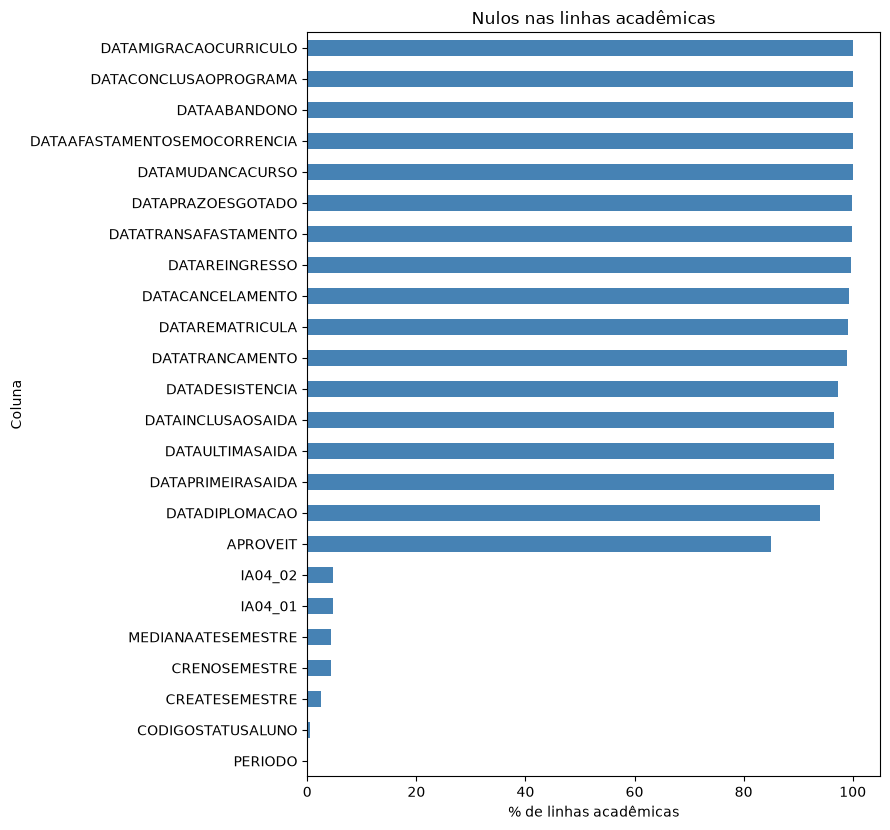

In [2]:
linhas = []
for origem, grupo in base.groupby('ORIGEMREGISTRO', dropna=False):
    for coluna in original.columns:
        mask = base.ORIGEMREGISTRO.eq(origem) & base[coluna].isna()
        qtd = int(mask.sum())
        complemento = base.ORIGEMREGISTRO.eq(origem) & base[coluna].notna()
        # Protege também o grupo complementar, que poderia ser deduzido do total.
        permitido = (qtd == 0 or alunos(mask) >= 10) and (not complemento.any() or alunos(complemento) >= 10)
        rotulo = f'Identificador {list(c for c in original.columns if c.startswith("HANDLE")).index(coluna) + 1}' if coluna.startswith('HANDLE') else coluna
        linhas.append({'Origem': origem, 'Coluna': rotulo, 'Nulos': qtd if permitido else '<10 alunos',
                       '% nulos': round(qtd / len(grupo) * 100, 2) if permitido else 'suprimido'})
nulos = pd.DataFrame(linhas)
display(nulos.set_index(['Origem', 'Coluna']))
graf = nulos[(nulos.Origem == 'ACADEMICA') & nulos['% nulos'].map(lambda x: isinstance(x, (int, float)) and x > 0)].sort_values('% nulos')
ax = graf.plot.barh(x='Coluna', y='% nulos', figsize=(9, max(4, len(graf)*.35)), legend=False, color='steelblue')
ax.set_xlabel('% de linhas acadêmicas'); ax.set_title('Nulos nas linhas acadêmicas')
plt.tight_layout(); plt.savefig(figuras / '02_nulos_academica.png', dpi=150); plt.show()

## Vazio e zero

APROVEIT vazio significa nenhum semestre aproveitado e pode ser convertido em zero em uma cópia para análise. Frequência e quantidade de disciplinas com faltas podem estar vazias sem turma ativa; os demais vazios acadêmicos devem ser investigados conforme a tabela acima. O CSV não permite confirmar diretamente a existência de turma ativa.

O total de disciplinas matriculadas não identifica diretamente turmas ativas: mesmo quando é maior que zero, não confirma que havia turma ativa para cálculo da frequência.

In [3]:
indicadores = ['IA04_01','IA04_02','IA75_01','IA75_02','IA75_03','IA75_04','IA75_05','IA34_03','IA65_03','ATIVCOMPL_MATRICULADAS','ATIVCOMPL_APROVADAS','ATIVCOMPL_REPROVADAS']
display(resumo({f'{c}: vazio em ACADEMICA': academica & base[c].isna() for c in indicadores}))
display(resumo({'APROVEIT vazio em ACADEMICA': academica & base.APROVEIT.isna(),
                'Frequência vazia com disciplinas matriculadas': academica & base.IA04_01.isna() & base.IA75_04.gt(0)}))

,Linhas
Verificação,
IA04_01: vazio em ACADEMICA,2136
IA04_02: vazio em ACADEMICA,2136
IA75_01: vazio em ACADEMICA,0
IA75_02: vazio em ACADEMICA,0
IA75_03: vazio em ACADEMICA,0
IA75_04: vazio em ACADEMICA,0
IA75_05: vazio em ACADEMICA,0
IA34_03: vazio em ACADEMICA,0
IA65_03: vazio em ACADEMICA,0


,Linhas
Verificação,
APROVEIT vazio em ACADEMICA,37744
Frequência vazia com disciplinas matriculadas,2080


## Conversão de números e datas

A leitura textual é usada somente para comparar valores preenchidos com os convertidos. Os identificadores não são apresentados.

In [4]:
numericas = ['PERIODO','CRENOSEMESTRE','CREATESEMESTRE','MEDIANAATESEMESTRE','APROVEIT','QUANTIDADEOCORRENCIAS','QTDOCORRENCIASSEMDATA'] + indicadores + [c for c in original if c.startswith('TEVE')]
datas = [c for c in original if c.startswith('DATA')]
perdas = {}
for c in numericas:
    convertido = pd.to_numeric(original[c].str.replace(',', '.', regex=False), errors='coerce')
    perdas[c] = original[c].notna() & convertido.isna()
for c in datas:
    perdas[c] = original[c].notna() & pd.to_datetime(original[c], format='%d/%m/%y', errors='coerce').isna()
display(resumo(perdas).rename_axis('Coluna'))

,Linhas
Coluna,
PERIODO,0
CRENOSEMESTRE,0
CREATESEMESTRE,0
MEDIANAATESEMESTRE,0
APROVEIT,0
QUANTIDADEOCORRENCIAS,0
QTDOCORRENCIASSEMDATA,0
IA04_01,0
IA04_02,0


## Domínios

PERIODO = 0 fora de GAE é uma limitação a esclarecer, não um erro confirmado. GAE é o código de aluno especial documentado em `docs/divergencias_legenda.md`.

In [5]:
contagens = ['APROVEIT','QUANTIDADEOCORRENCIAS','QTDOCORRENCIASSEMDATA','IA04_02','IA75_01','IA75_02','IA75_03','IA75_04','IA75_05','IA34_03','IA65_03','ATIVCOMPL_MATRICULADAS','ATIVCOMPL_APROVADAS','ATIVCOMPL_REPROVADAS']
flags = [c for c in base if c.startswith('TEVE')]
checks = {f'{c}: fora de 0–100': base[c].notna() & ~base[c].between(0,100) for c in ['CRENOSEMESTRE','CREATESEMESTRE','MEDIANAATESEMESTRE','IA04_01']}
checks.update({f'{c}: negativa ou não inteira': base[c].notna() & ((base[c] < 0) | (base[c] % 1 != 0)) for c in contagens})
checks.update({f'{c}: diferente de 0/1': base[c].notna() & ~base[c].isin([0,1]) for c in flags})
checks.update({'PERIODO fora de 0–10 ou não inteiro': base.PERIODO.notna() & (~base.PERIODO.between(0,10) | (base.PERIODO % 1 != 0)),
               'PERIODO zero fora de GAE': base.PERIODO.eq(0) & base.SIGLACURSO.ne('GAE')})
display(resumo(checks))

,Linhas
Verificação,
CRENOSEMESTRE: fora de 0–100,0
CREATESEMESTRE: fora de 0–100,0
MEDIANAATESEMESTRE: fora de 0–100,0
IA04_01: fora de 0–100,<10 alunos
APROVEIT: negativa ou não inteira,0
QUANTIDADEOCORRENCIAS: negativa ou não inteira,0
QTDOCORRENCIASSEMDATA: negativa ou não inteira,0
IA04_02: negativa ou não inteira,0
IA75_01: negativa ou não inteira,0


## Coerência entre colunas

As comparações exigem todos os campos envolvidos preenchidos. Somatórios maiores que o total são sinais a investigar, não prova automática de erro.

In [6]:
checks = {}
for nome, partes, total in [('Disciplinas', ['IA75_03','IA34_03','IA65_03'], 'IA75_04'), ('Atividades complementares', ['ATIVCOMPL_APROVADAS','ATIVCOMPL_REPROVADAS'], 'ATIVCOMPL_MATRICULADAS')]:
    valido = base[partes + [total]].notna().all(axis=1)
    checks[f'{nome}: soma superior às matriculadas'] = valido & base[partes].sum(axis=1).gt(base[total])
    checks[f'{nome}: comparação incompleta'] = academica & ~valido
checks['Obrigatórias concluídas acima da grade'] = base.IA75_02.notna() & base.IA75_01.notna() & base.IA75_02.gt(base.IA75_01)
checks['Obrigatórias: comparação incompleta'] = academica & (base.IA75_02.isna() | base.IA75_01.isna())
checks['Acadêmica sem matrícula efetivada S'] = academica & base.MATRICULAEFETIVADA.ne('S').fillna(True)
for flag in flags:
    data = 'DATA' + flag[4:]
    if data in base:
        checks[f'{flag}: flag 1 sem data'] = base[flag].eq(1) & base[data].isna()
        checks[f'{flag}: data sem flag 1'] = base[data].notna() & ~base[flag].eq(1)
display(resumo(checks))

,Linhas
Verificação,
Disciplinas: soma superior às matriculadas,21
Disciplinas: comparação incompleta,0
Atividades complementares: soma superior às matriculadas,0
Atividades complementares: comparação incompleta,0
Obrigatórias concluídas acima da grade,0
Obrigatórias: comparação incompleta,0
Acadêmica sem matrícula efetivada S,0
TEVEDESISTENCIA: flag 1 sem data,0
TEVEDESISTENCIA: data sem flag 1,0


## Duplicidade e múltiplos vínculos

A chave de vínculo identifica repetições; pares aluno-semestre com mais de uma linha podem refletir mudança de curso ou migração. A consolidação será definida na issue #6. Contagens de pares e linhas são suprimidas se envolverem menos de 10 alunos.

In [7]:
chave = ['HANDLEALUNO','ANOSEMESTRE','HANDLEALUNOCURRICULO']
duplicada = base.duplicated(chave, keep=False)
extra = base.duplicated(chave, keep='first')
display(resumo({'Linhas pertencentes a chaves repetidas': duplicada, 'Linhas excedentes na chave': extra}))
tamanhos = base.groupby(['HANDLEALUNO','ANOSEMESTRE'], dropna=False).size()
pares = tamanhos[tamanhos > 1]
n_pessoas = pares.index.get_level_values(0).nunique()
display(pd.DataFrame({'Medida':['Pares aluno-semestre com múltiplas linhas'], 'Contagem':[seguro(len(pares), n_pessoas)]}).set_index('Medida'))
multi = base.set_index(['HANDLEALUNO','ANOSEMESTRE']).index.isin(pares.index)
display(resumo({f'Linhas de pares múltiplos — {o}': pd.Series(multi, index=base.index) & base.ORIGEMREGISTRO.eq(o) for o in ['ACADEMICA','OCORRENCIA']}))

,Linhas
Verificação,
Linhas pertencentes a chaves repetidas,0
Linhas excedentes na chave,0


,Contagem
Medida,
Pares aluno-semestre com múltiplas linhas,8825


,Linhas
Verificação,
Linhas de pares múltiplos — ACADEMICA,8276
Linhas de pares múltiplos — OCORRENCIA,11408


## Cobertura temporal

Os totais por semestre contam linhas e alunos distintos; alunos podem aparecer em mais de um semestre. Ingresso se refere ao currículo e o mesmo aluno pode aparecer em mais de um ano. Células com menos de 10 alunos são omitidas do gráfico. A legenda aponta estabilização a partir de 2014 e composição parcial entre 2009 e 2013; a série deve ser interpretada visualmente, sem estabelecer um limiar automático.

Na série desta base, o crescimento inicial termina por volta de 2014, mas há oscilações e queda posterior: isso não estabelece estabilidade permanente. Os picos de linhas e de alunos distintos não precisam coincidir, pois pode haver mais de uma linha por aluno no semestre.

,Linhas,Alunos
ANOSEMESTRE,,
2009/1,257.0,213.0
2009/2,355.0,310.0
2010/1,721.0,560.0
2010/2,787.0,656.0
2011/1,1223.0,948.0
2011/2,1295.0,1070.0
2012/1,1834.0,1364.0
2012/2,1757.0,1485.0
2013/1,2140.0,1789.0


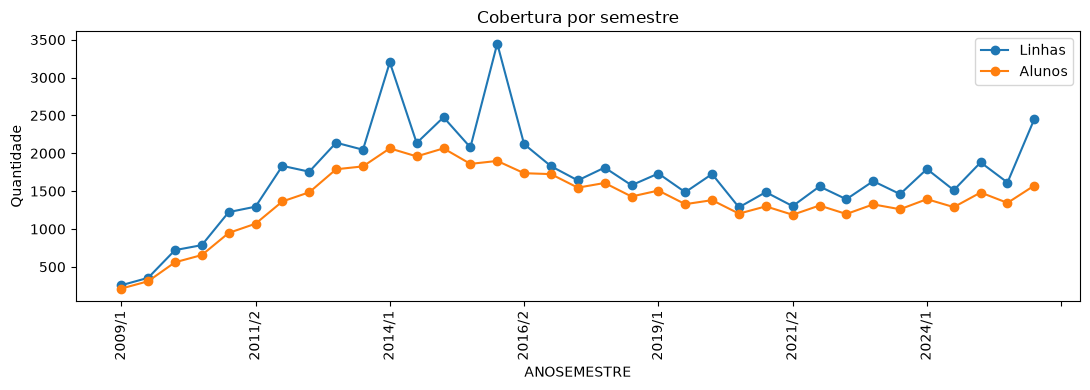

,Alunos distintos
ANO_INGRESSO,
2009,336
2010,439
2011,605
2012,628
2013,722
2014,672
2015,534
2016,422
2017,374


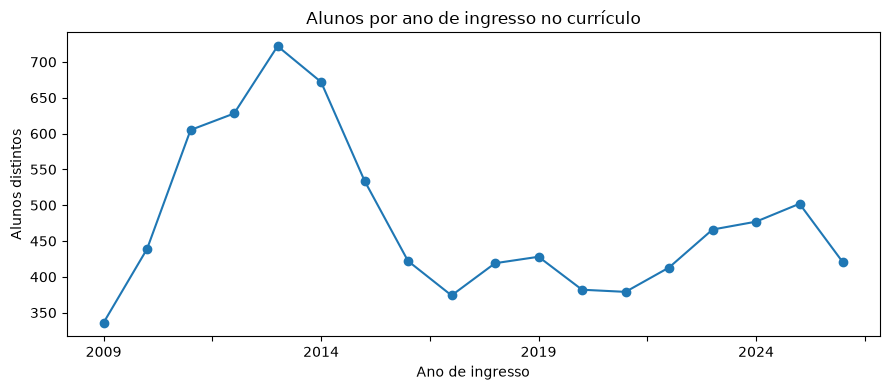

In [8]:
sem = base.groupby('ANOSEMESTRE').agg(Linhas=('ORIGEMREGISTRO','size'), Alunos=('HANDLEALUNO','nunique')).sort_index()
sem.loc[sem.Alunos < 10, ['Linhas','Alunos']] = np.nan
display(sem.fillna('suprimido'))
ax = sem.plot(marker='o', figsize=(11,4), title='Cobertura por semestre'); ax.set_ylabel('Quantidade'); ax.tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.savefig(figuras / '02_cobertura_semestre.png', dpi=150); plt.show()
ano = base.assign(ANO_INGRESSO=base.INGRESSO.str.slice(0,4)).groupby('ANO_INGRESSO').HANDLEALUNO.nunique().sort_index()
ano = ano.where(ano >= 10)
display(ano.rename('Alunos distintos').fillna('suprimido').to_frame())
ax = ano.plot(marker='o', figsize=(9,4), title='Alunos por ano de ingresso no currículo'); ax.set_ylabel('Alunos distintos'); ax.set_xlabel('Ano de ingresso')
plt.tight_layout(); plt.savefig(figuras / '02_ingresso_ano.png', dpi=150); plt.show()

## Colunas sem uso e status desconhecido

A ausência de informação financeira e socioeconômica limita as conclusões. Os resultados descrevem somente a base.

In [9]:
display(resumo({'Conclusão de programa: flag diferente de zero': base.TEVECONCLUSAOPROGRAMA.ne(0) & base.TEVECONCLUSAOPROGRAMA.notna(),
                'Conclusão de programa: data preenchida': base.DATACONCLUSAOPROGRAMA.notna(),
                'Ocorrências sem data: diferente de zero ou vazio': base.QTDOCORRENCIASSEMDATA.ne(0) | base.QTDOCORRENCIASSEMDATA.isna(),
                'Status desconhecido — acadêmica': academica & base.STATUSALUNO.eq('Desconhecido'),
                'Status desconhecido — ocorrência': ocorrencia & base.STATUSALUNO.eq('Desconhecido')}))

,Linhas
Verificação,
Conclusão de programa: flag diferente de zero,0
Conclusão de programa: data preenchida,0
Ocorrências sem data: diferente de zero ou vazio,0
Status desconhecido — acadêmica,249
Status desconhecido — ocorrência,11102


## Decisões de tratamento

**Propostas para revisão e aprovação pela Karolina no PR.** As contagens abaixo são de linhas, salvo indicação diferente, e foram retiradas das células executadas. Grupos pequenos permanecem suprimidos.

- **Vazios estruturais:** os 12 indicadores de frequência, disciplinas e atividades estão vazios nas linhas de ocorrência, como prevê a legenda. Manter essas linhas e analisar tais indicadores apenas quando disponíveis. Datas de ocorrência vazias sem flag são esperadas; não substituí-las por datas artificiais.
- **Vazios acadêmicos:** frequência e contagem de disciplinas com faltas têm 2.136 vazios cada; nas demais contagens semestrais verificadas não há vazios acadêmicos. Em 2.080 linhas a frequência está vazia apesar de haver disciplinas matriculadas. Isso não comprova erro nem ausência de turma ativa, pois a contagem de matrículas não identifica a situação das turmas. Manter como ausente e esclarecer com a fonte antes de imputar. Também há vazios em período (27), CRE semestral (1.965), CRE acumulado (1.141), mediana (1.973), sexo (grupo pequeno suprimido) e código de status (249). Não substituí-los por zero; excluir da análise específica quando necessário e informar a cobertura.
- **APROVEIT:** há 37.744 vazios acadêmicos. Em cópia de análise, tratá-los como zero conforme a legenda; não alterar o arquivo. A inclusão de estudos externos não foi confirmada e é limitação da interpretação.
- **Conversões:** não houve perdas nas colunas numéricas e datas auditadas. Manter os tipos convertidos; monitorar perdas em futuras versões. A auditoria não cobre identificadores, lidos separadamente pelo carregador.
- **Domínios:** há um grupo pequeno suprimido com frequência fora de 0–100. Tratar esses valores como ausentes apenas nas análises de frequência. Não foram encontrados valores fora de 0–100 nos dois CREs e na mediana, nem contagens negativas ou fracionárias, flags fora de 0/1 ou períodos fora de 0–10 ou fracionários. Período zero fora de GAE ocorre em grupo pequeno suprimido: manter e registrar como limitação, pois seu significado não foi confirmado.
- **Coerência:** em 21 linhas a soma de aprovadas, reprovadas e retiradas supera o número de disciplinas matriculadas. Investigar as definições com a fonte; até esclarecer, excluir essas observações de análises que dependam da relação entre essas contagens, preservando as linhas e sem presumir qual campo está errado. Não foram observadas violações nas comparações das atividades complementares e da grade, nem matrícula acadêmica diferente de S, nem discordância entre flags e datas. O critério de reprovação em atividades complementares continua sem confirmação.
- **Vínculos e duplicidade:** não houve chave aluno–semestre–vínculo repetida. Há 8.825 pares aluno–semestre com mais de uma linha; suas linhas incluem 8.276 acadêmicas e 11.408 de ocorrência. Não deduplicar nem consolidar automaticamente: a unidade e a regra serão definidas na issue #6.
- **Status desconhecido:** há 249 linhas acadêmicas e 11.102 de ocorrência com esse status. Manter como categoria de informação ausente, sem interpretar como situação acadêmica conhecida, e informar a cobertura em análises de status.
- **Colunas sem uso:** a flag de conclusão de programa é sempre zero, sua data está sempre vazia e a contagem de ocorrências sem data é sempre zero. Propor sua exclusão das análises e modelos por não apresentarem variação nesta base; preservar a base original.
- **Cobertura e limites:** o crescimento inicial da série se atenua por volta de 2014, mas há oscilações e redução posterior; não afirmar estabilidade permanente. De 2009 a 2013 a composição é parcial segundo a legenda. Ingresso é no currículo e um aluno pode aparecer em mais de um ano. A ausência de dados financeiros e socioeconômicos limita as conclusões; resultados descrevem a base e não estabelecem causalidade.
